In [1]:
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

nltk.download('gutenberg')
nltk.download('brown')
from nltk.corpus import gutenberg, brown

[nltk_data] Downloading package gutenberg to /root/nltk_data...
[nltk_data]   Unzipping corpora/gutenberg.zip.
[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.


In [2]:
# Q1: Corpus = "Alice's Adventures in Wonderland" by Lewis Carroll (NLTK Gutenberg)
# Q2: A "word" = lowercased purely alphabetic token (no punctuation, no numbers, no lemmatization)
words = [w.lower() for w in gutenberg.words('carroll-alice.txt') if w.isalpha()]
N = len(words)
counts = Counter(words)

print(f"Total words (tokens): {N}")
print(f"Unique words (types): {len(counts)}")

Total words (tokens): 27333
Unique words (types): 2569


**Q1. Corpus.** I chose *Alice's Adventures in Wonderland* by Lewis Carroll, loaded from the NLTK Gutenberg collection (`carroll-alice.txt`).

**Q2. Total unique words.** I defined a word as a lowercased, purely alphabetic token, without lemmatization. Under this definition the corpus has 27,333 total words (tokens) and 2,569 unique words (types). Note that the NLTK tokenizer splits contractions (e.g. "didn't" becomes "didn" and "t"), so fragments like "s", "t", "ll" and "ve" are counted as separate words.

In [3]:
cum = 0
for rank, (word, c) in enumerate(counts.most_common(), start=1):
    cum += c
    if cum >= N / 2:
        print(f"The {rank} most frequent words account for half of all words in the corpus.")
        break

The 54 most frequent words account for half of all words in the corpus.


**Q3. Half of the corpus.** The 54 most frequent words account for half of all 27,333 words in the corpus. That is only about 2% of the 2,569 unique words, which shows how heavily the text relies on a small set of very common words.

In [4]:
top200 = pd.DataFrame(counts.most_common(200), columns=["word", "count"])
top200["rank"] = range(1, 201)
top200["rel_freq"] = top200["count"] / N
top200[["rank", "word", "count", "rel_freq"]]

,rank,word,count,rel_freq
0,1,the,1642,0.060074
1,2,and,872,0.031903
2,3,to,729,0.026671
3,4,a,632,0.023122
4,5,it,595,0.021769
...,...,...,...,...
195,196,ever,21,0.000768
196,197,find,21,0.000768
197,198,minute,21,0.000768
198,199,till,21,0.000768


**Q4. The 200 most frequent words.** The table above lists the 200 most frequent words with their counts and relative frequencies. The top of the list is dominated by function words: "the" (1,642 occurrences, about 6.0% of all words), "and", "to", "a", "it", "she", "i", "of". The first book-specific word is "said" (rank 9), which reflects the amount of dialogue, followed by "alice" at rank 11.

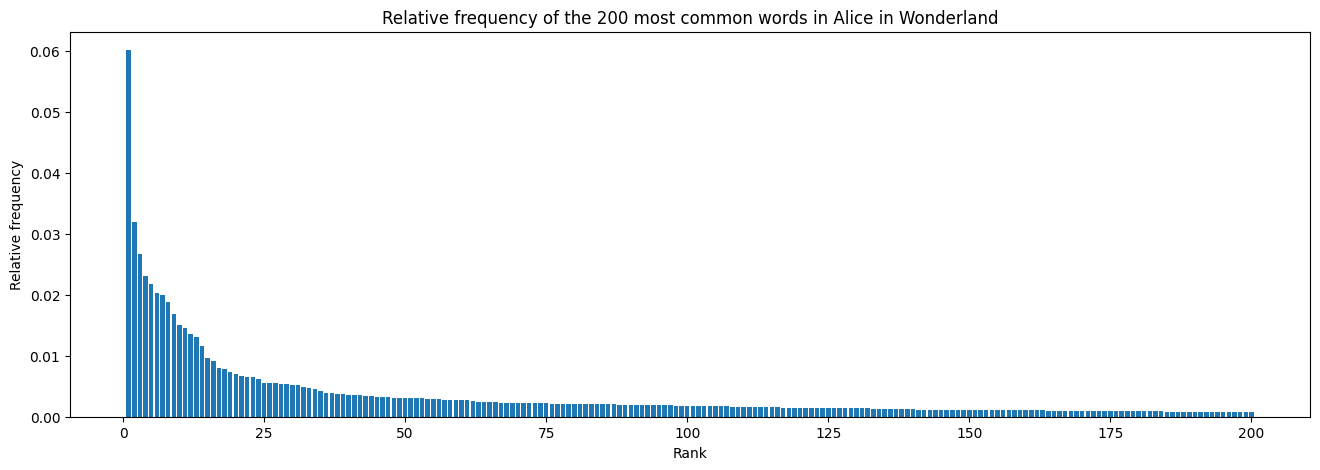

In [5]:
fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(top200["rank"], top200["rel_freq"], width=0.8)
ax.set_xlabel("Rank")
ax.set_ylabel("Relative frequency")
ax.set_title("Relative frequency of the 200 most common words in Alice in Wonderland")
plt.show()

**Q5. Relative frequency graph.** The bar chart shows the relative frequency of the 200 most common words. The distribution is extremely skewed: "the" alone makes up about 6% of the text, the next few words fall off quickly, and from about rank 30 onward the bars are nearly flat and very small. This long-tail shape is what we expect from natural language, and the log-log plot below looks at it more closely.

Slope = -0.895, R^2 = 0.987


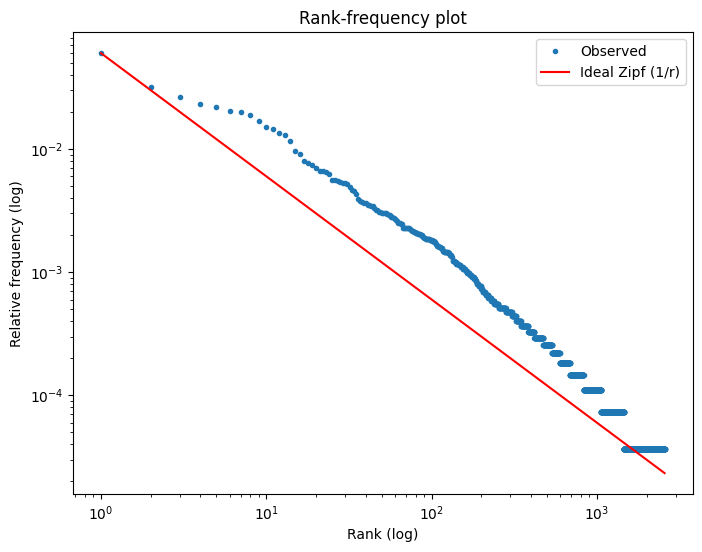

In [6]:
# Zipf's law: f(r) ~ C / r, i.e. a straight line with slope about -1 on a log-log plot
ranks = np.arange(1, len(counts) + 1)
freqs = np.array([c for _, c in counts.most_common()]) / N

# Fit a line on the top 200 words
x = np.log(ranks[:200])
y = np.log(freqs[:200])
slope, intercept = np.polyfit(x, y, 1)
r2 = np.corrcoef(x, y)[0, 1] ** 2
print(f"Slope = {slope:.3f}, R^2 = {r2:.3f}")

plt.figure(figsize=(8, 6))
plt.loglog(ranks, freqs, '.', label="Observed")
plt.loglog(ranks, freqs[0] / ranks, 'r-', label="Ideal Zipf (1/r)")
plt.xlabel("Rank (log)")
plt.ylabel("Relative frequency (log)")
plt.legend()
plt.title("Rank-frequency plot")
plt.show()

**Q6. Does the observed relative frequency follow Zipf's law?**

Approximately, yes. On the log-log rank-frequency plot the observed points form a nearly straight, downward-sloping line, which is the signature of a power law. A linear fit on the 200 most frequent words gives a slope of -0.895 with R^2 = 0.987, which is close to the slope of -1 predicted by Zipf's law (f ~ 1/r).

There are some deviations:
- **Slope is shallower than -1.** The observed frequencies lie above the ideal 1/r curve (which is anchored to the frequency of the top word), so frequency falls off a bit more slowly than Zipf predicts. In particular, words ranked roughly 3-10 are more frequent than 1/r would suggest.
- **The tail looks like a staircase.** Many words occur only once, twice or three times. Because counts are integers and the corpus is small ( 27,333 words), the low-frequency end cannot follow a smooth line.

Overall, Zipf's law is a good description of this corpus, but not an exact one, which is typical for a short text.

In [7]:
brown_words = [w.lower() for w in brown.words() if w.isalpha()]
brown_counts = Counter(brown_words)
M = len(brown_words)

# Words much more frequent in Alice than in general English (Brown)
rows = []
for w, c in counts.most_common(300):
    alice_f = c / N
    brown_f = (brown_counts.get(w, 0) + 1) / M  # +1 smoothing to avoid division by zero
    rows.append((w, alice_f, brown_f, alice_f / brown_f))

over = pd.DataFrame(rows, columns=["word", "alice_freq", "brown_freq", "ratio"])
over.sort_values("ratio", ascending=False).head(20)

,word,alice_freq,brown_freq,ratio
80,ll,0.002085,0.000001,2047.261991
83,hatter,0.002049,0.000001,2011.345114
86,gryphon,0.002012,0.000001,1975.428237
110,ve,0.001610,0.000001,1580.342590
124,dormouse,0.001463,0.000001,1436.675081
10,alice,0.014561,0.000015,952.994471
115,duchess,0.001537,0.000002,754.254418
238,doesn,0.000585,0.000001,574.670033
148,hare,0.001134,0.000002,556.711594
261,dinah,0.000512,0.000001,502.836278


**Q7. How does the word frequency in this corpus differ from "all words in all corpora"?**

I used the Brown corpus as a rough proxy for general English and compared relative frequencies.

- **Function words are the same.** Words like "the", "and", "to" and "a" are at the top of nearly every English corpus, and Alice is no exception. This part of the distribution is a property of the language, not of the book.
- **Character names dominate the differences.** The words with the largest frequency ratios are Alice, Hatter, Gryphon, Dormouse, Duchess, Hare, Dinah, Caterpillar, Dodo, Footman, Turtle, Mock and Rabbit. Many of these do not appear in Brown at all (the ratios for them are inflated by my +1 smoothing and should be read as "absent from Brown", not as exact numbers). In a general corpus, proper names are spread over thousands of different people and places, whereas in a single novel a few names are repeated constantly.
- **Genre and style.** This is a children's story with a lot of dialogue, written in Victorian English, while Brown is a balanced collection of 1960s American texts (news, fiction, scientific writing and so on). Because of this, the vocabulary of Alice is narrower and more repetitive.
- **Tokenization artifacts.** Words such as "ll", "ve", "re", "s", "didn", "doesn" and "wouldn" appear in the list because contractions (I'll, didn't) are split into pieces by the tokenizer. They are an artifact of preprocessing and of the different tokenization of the two corpora, not a real feature of the text.
- **Size.** Alice is small (about 27,333 words) compared to Brown (about one million words), so its rank-frequency curve is noisier, especially in the tail.

Caveat: Brown is only one corpus and is not truly "all corpora", so these differences describe Alice relative to a mid-century balanced American English sample.